# Frequency of errors in the corpus

How often each error type and each error message appears in the entries, and how the retries ended. Run from this directory, it reads `../knowledge/entries`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from pipelines_knowledge.convert import _error_key
from pipelines_watch import entries

sns.set_theme(style="whitegrid")
df = pd.DataFrame([{**e.model_dump(exclude={"snippet"}), "error": _error_key(e)}
                   for e, _ in entries.load_all("../knowledge") if e.snippet.strip()])
print(len(df), "entries,", df.error.nunique(), "distinct errors")

983 entries, 134 distinct errors


## By error type

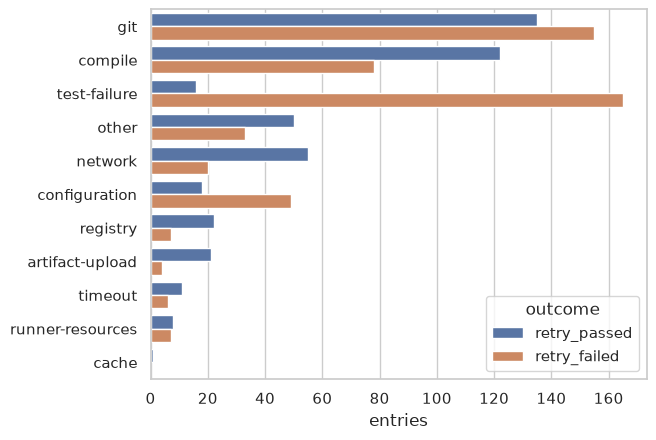

In [2]:
order = df.error_type.value_counts().index
ax = sns.countplot(data=df, y="error_type", hue="outcome", order=order, hue_order=["retry_passed", "retry_failed"])
ax.set(xlabel="entries", ylabel="")
plt.show()

## The 15 most frequent errors

Errors are matched on the first snippet line with numbers and paths blanked, the same key that `convert` uses for the success rate.

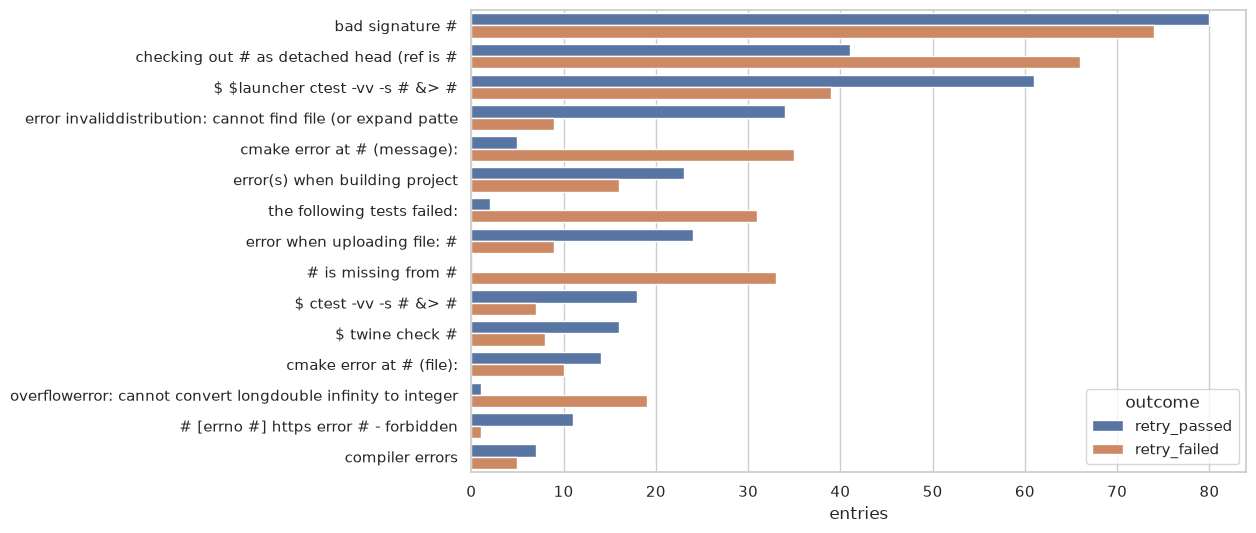

In [3]:
df["label"] = df.error.str[:60].str.replace("$", r"\$", regex=False)  # "$" would start math text
top = df.label.value_counts().head(15).index
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df[df.label.isin(top)], y="label", hue="outcome", order=top, hue_order=["retry_passed", "retry_failed"])
ax.set(xlabel="entries", ylabel="")
plt.show()

## How many errors are seen only once

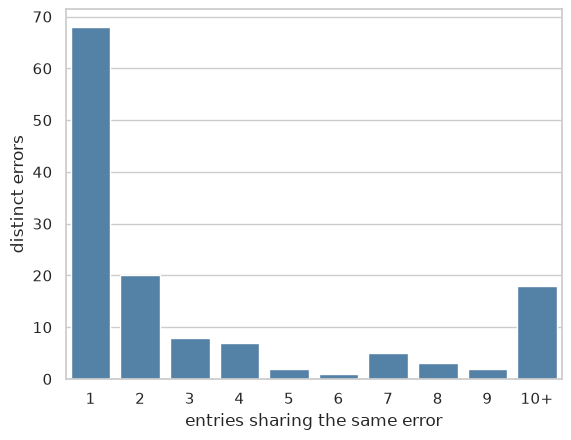

In [4]:
sizes = df.error.value_counts().clip(upper=10).value_counts().sort_index()
ax = sns.barplot(x=sizes.index.astype(str).str.replace("10", "10+"), y=sizes.values, color="steelblue")
ax.set(xlabel="entries sharing the same error", ylabel="distinct errors")
plt.show()

## The errors seen only once

What the single-entry errors are: their type, their outcome, and whether they are near duplicates of a more frequent error that the matching key failed to merge.

68 entries, 7% of the corpus


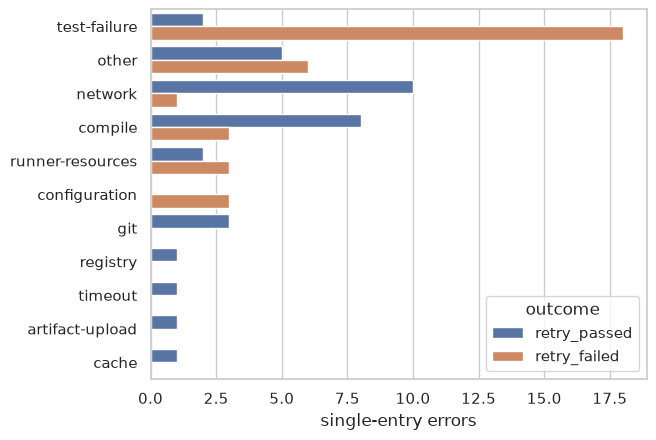

In [5]:
counts = df.error.value_counts()
single = df[df.error.map(counts) == 1]
print(len(single), "entries,", f"{len(single) / len(df):.0%} of the corpus")
ax = sns.countplot(data=single, y="error_type", hue="outcome", order=single.error_type.value_counts().index,
                   hue_order=["retry_passed", "retry_failed"])
ax.set(xlabel="single-entry errors", ylabel="")
plt.show()

In [6]:
import difflib

frequent = list(counts[counts > 1].index)
single = single.assign(closest=single.error.map(lambda e: (difflib.get_close_matches(e, frequent, n=1, cutoff=0.8) or [None])[0]))
merged = single.closest.notna()
print(merged.sum(), "of", len(single), "single errors are close (ratio >= 0.8) to a more frequent one")
pd.set_option("display.max_colwidth", 70, "display.width", 200)
single[merged][["error", "closest"]].head(15)

6 of 68 single errors are close (ratio >= 0.8) to a more frequent one


,error,closest
0,cannot fork() for index-pack: resource temporarily unavailable,cannot fork() for unpack-objects: resource temporarily unavailable
197,# - vtk::renderingwebgpucxx-testcomputeocclusioncullingresize (fai...,# - vtk::renderingwebgpucxx-testcomputeocclusionculling (failed) v...
199,"uploading artifacts as ""archive"" to coordinator... # bad gateway c...","uploading artifacts as ""archive"" to coordinator... # request entit..."
365,# - vtk::renderingvolumecxx-testgpuraycastcamerainsidesmallspacing...,# - vtk::renderingvolumecxx-testgpuvolumeraycastmapper (failed) vt...
621,checking out # as detached head (ref is v#.#.#)...,checking out # as detached head (ref is #
760,# - vtk::renderinglicopengl#cxx-testimagedatalic#d (failed) vtk::r...,# - vtk::renderinglicopengl#cxx-testimagedatalic#dserdes (failed) ...


In [7]:
print("no close match, genuinely rare:", (~merged).sum())
single[~merged][["error_type", "outcome", "error"]].sort_values("error_type").head(25)

no close match, genuinely rare: 62


,error_type,outcome,error
599,cache,retry_passed,sccache: error: failed to get stats from server
937,compile,retry_failed,..........................................!! size of output: #k
823,compile,retry_passed,......................!!!!!!!!!!!!!!!!!!!! size of output: #k
822,compile,retry_passed,..................!!!!!!!!!!!!!!!!!!!!!!! size of output: #k
821,compile,retry_passed,!!!!! size of output: #k
820,compile,retry_passed,.......................!..!!!!!!!!!!!!!.!!!!!!!!!! size: #k
619,compile,retry_passed,...............!! size of output: #k
319,compile,retry_passed,!!!!!!!!.!!!!!!!!!!!!!!!!!!!!!!!!!! size of output: #k
310,compile,retry_passed,.............................................!!... size: #k
295,compile,retry_passed,...................................!!.!!!......!! size of output: #k
